# Market regime detection with a Gaussian HMM

Runs the full pipeline from `src/`.

In [1]:
import warnings

import numpy as np
import pandas as pd
from scipy.optimize import brentq

from src.data import load_prices, emissions, FEATURE_COLS, DATA_DIR
from src.hmm import fit_hmm, label_states, decode, transition_report, select_n_states
from src.backtest import (walk_forward_states, overlay, baselines, restrict, metrics, leakage_check,
                          apply_costs, sweep_exposure_maps)
from src.plots import (plot_regime_price, plot_equity_curves, plot_drawdowns,
                       plot_transition_heatmap)
from src.crosscheck import fit_markov_switching, ranked_regime_path, agreement

# hmmlearn raises a numpy deprecation warning on every fit
warnings.filterwarnings('ignore', category=DeprecationWarning)
pd.options.display.float_format = '{:.3f}'.format

## 1. Data and features

In [2]:
prices = load_prices()
X, dates, next_day_ret = emissions(prices)
print(X.shape, dates.min().date(), '->', dates.max().date())

(6690, 3) 2000-02-01 -> 2026-09-08


## 2. Number of states

Fit on 2000-2018, score BIC and log-likelihood on 2019 onward. Both keep improving through 5 states, so there is no flat spot to pick. After testing 2 to 5 states, 3 is chosen because the gains decelerate and states beyond 3 only split the calm regime without a distinct interpretation. The 2019+ likelihood overlaps the walk-forward window, so this choice is not fully out of sample.

In [3]:
train_end = int((dates < '2019-01-01').sum())
pd.DataFrame(select_n_states(X, train_end)).set_index('n')

,ll_train,ll_test,bic,n_params,converged
n,,,,,
2,-11864.572,-4951.050,23906.968,21,True
3,-9623.534,-4170.305,19543.441,35,True
4,-8279.503,-3570.920,16990.864,51,True
5,-7229.295,-3256.777,15042.867,69,True


## 3. Full-sample fit (interpretation only)

Viterbi path, state means, transition matrix, implied vs realised dwell times.

In [4]:
model = fit_hmm(X, n_states=3)
mapping = label_states(model)                        # raw state -> vol rank
viterbi, _ = decode(model, X)
lut = np.array([mapping[k] for k in range(3)])
ranked = lut[viterbi]
rep = transition_report(model, viterbi)
order = np.argsort(model.means_[:, FEATURE_COLS.index('Vol20')])
state_table = pd.DataFrame(model.means_[order], columns=FEATURE_COLS, index=['calm', 'choppy', 'crisis'])
state_table['stationary'] = rep['stationary']
state_table['implied_dwell'] = rep['implied_dwell']
state_table['realised_dwell'] = rep['realised_dwell']
state_table

,Return,Vol20,Range,stationary,implied_dwell,realised_dwell
calm,0.059,0.581,0.774,0.432,46.104,47.983
choppy,0.024,1.058,1.307,0.408,29.140,32.151
crisis,-0.059,2.127,2.586,0.159,29.353,34.867


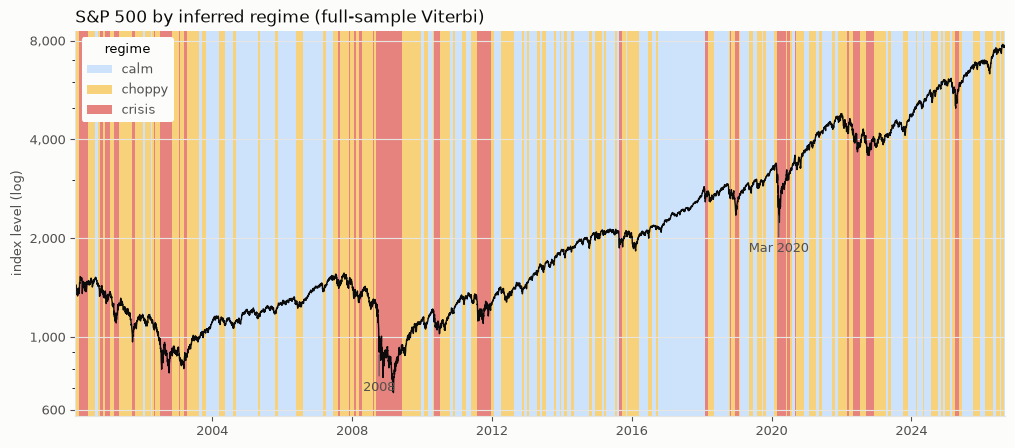

In [5]:
plot_regime_price(prices, dates, ranked);

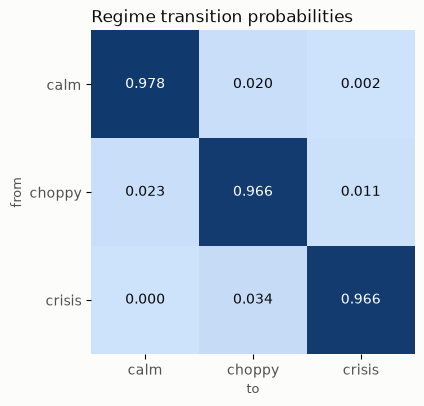

In [6]:
plot_transition_heatmap(rep['P']);

## 4. Walk-forward overlay vs baselines

Expanding window (`min_train=1000`, refit every 21 days), forward-filtered states. The fit takes about 6 minutes, so the states are cached in `data/`.

In [7]:
MIN_TRAIN, STEP, N_STATES = 1000, 21, 3
cache = DATA_DIR / f'wf_states_{MIN_TRAIN}_{STEP}_{N_STATES}.parquet'   # parameters in the name, so a changed setting can't reuse it
if cache.exists():
    states = pd.read_parquet(cache)['state']
else:
    states = walk_forward_states(X, dates, min_train=MIN_TRAIN, step=STEP, n_states=N_STATES)
    states.to_frame('state').to_parquet(cache)
assert states.index.equals(dates[MIN_TRAIN:]), 'stale cache: delete it and re-run'
print(states.index.min().date(), '->', states.index.max().date(), len(states), 'days')
states.map({0: 'calm', 1: 'choppy', 2: 'crisis'}).value_counts(normalize=True)

2004-01-27 -> 2026-09-08 5690 days


state
calm     0.489
choppy   0.359
crisis   0.152
Name: proportion, dtype: float64

In [8]:
HEADLINE_MAP = {0: 1.0, 1: 0.5, 2: 0.0}
res_overlay = overlay(states, next_day_ret, HEADLINE_MAP)
# baselines use the full history for warm-up, then get cut to the OOS days
base = {k: restrict(v, res_overlay.index) for k, v in baselines(next_day_ret).items()}
results = {'regime overlay': res_overlay, 'buy & hold': base['buy_and_hold'],
           'fixed 60%': base['fixed_60'], 'vol target': base['vol_target']}
table = pd.DataFrame({k: metrics(v['strat_ret'], v['exposure']) for k, v in results.items()}).T
table['dd_duration'] = table['dd_duration'].astype(int)
table

,ann_return,ann_vol,sharpe,sortino,max_dd,dd_duration,annual_turnover
regime overlay,0.061,0.090,0.706,0.968,-0.149,673,6.024
buy & hold,0.088,0.187,0.543,0.761,-0.568,1375,0.000
fixed 60%,0.056,0.112,0.543,0.761,-0.380,1242,0.000
vol target,0.118,0.182,0.707,0.980,-0.437,873,4.214


In [9]:
leakage_check(states, next_day_ret, HEADLINE_MAP)

honest Sharpe 0.706 | shifted Sharpe 1.028
No look-ahead detected


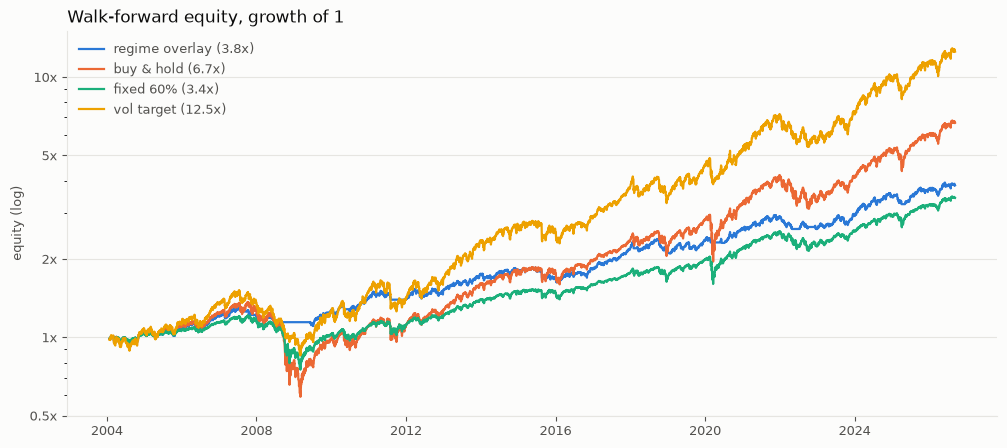

In [10]:
plot_equity_curves(results);

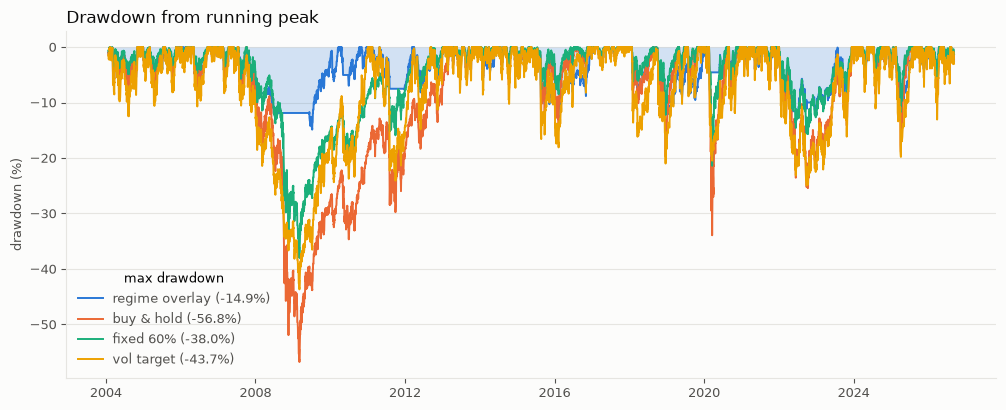

In [11]:
plot_drawdowns(results);

## 5. Exposure maps and transaction costs

In [12]:
maps = {'1.0 / 0.5 / 0.0 (headline)': HEADLINE_MAP,
        '1.0 / 0.6 / 0.2': {0: 1.0, 1: 0.6, 2: 0.2},
        '1.0 / 0.75 / 0.25': {0: 1.0, 1: 0.75, 2: 0.25},
        '1.0 / 1.0 / 0.0 (crisis only)': {0: 1.0, 1: 1.0, 2: 0.0}}
sweep_exposure_maps(states, next_day_ret, maps, cost_bps=5)

,ann_return,sharpe,max_dd,annual_turnover,net_ann_return,net_sharpe
map,,,,,,
1.0 / 0.5 / 0.0 (headline),0.061,0.706,-0.149,6.024,0.058,0.672
1.0 / 0.6 / 0.2,0.069,0.714,-0.222,4.819,0.066,0.690
1.0 / 0.75 / 0.25,0.078,0.731,-0.266,3.942,0.076,0.713
1.0 / 1.0 / 0.0 (crisis only),0.091,0.773,-0.260,3.721,0.089,0.758


In [13]:
# net Sharpe of every strategy at several per-trade cost assumptions
bps_grid = [0, 2, 5, 10]
net_sharpe = pd.DataFrame({
    name: [metrics(apply_costs(f['strat_ret'], f['exposure'], b), f['exposure'])['sharpe'] for b in bps_grid]
    for name, f in results.items()}, index=[f'{b} bps' for b in bps_grid])
net_sharpe

,regime overlay,buy & hold,fixed 60%,vol target
0 bps,0.706,0.543,0.543,0.707
2 bps,0.692,0.543,0.543,0.702
5 bps,0.672,0.543,0.543,0.695
10 bps,0.638,0.542,0.542,0.683


In [14]:
# cost at which the overlay's net Sharpe falls to the vol-target's
def gap(bps):
    o, v = results['regime overlay'], results['vol target']
    return (metrics(apply_costs(o['strat_ret'], o['exposure'], bps), o['exposure'])['sharpe']
            - metrics(apply_costs(v['strat_ret'], v['exposure'], bps), v['exposure'])['sharpe'])

if gap(0) > 0 > gap(500):
    print(f'break-even cost: {brentq(gap, 0, 500):.1f} bps per unit of exposure traded')
else:
    print('no break-even in 0-500 bps: gap at 0 bps =', round(gap(0), 3), '| at 500 bps =', round(gap(500), 3))

no break-even in 0-500 bps: gap at 0 bps = -0.001 | at 500 bps = -1.423


## 6. Cross-check: Markov-switching regression

`MarkovRegression` on the 100x log return only (switching mean and variance), against the HMM's full-sample Viterbi path.

In [15]:
ms = fit_markov_switching(pd.Series(X[:, FEATURE_COLS.index('Return')], index=dates), k_regimes=3)
sigma2 = np.array([ms.params[f'sigma2[{i}]'] for i in range(3)])
const = np.array([ms.params[f'const[{i}]'] for i in range(3)])
o = np.argsort(sigma2)
pd.DataFrame({'mean_ret': const[o], 'vol': np.sqrt(sigma2[o]), 'expected_dwell': np.asarray(ms.expected_durations)[o]},
             index=['calm', 'choppy', 'crisis'])

,mean_ret,vol,expected_dwell
calm,0.108,0.554,37.944
choppy,-0.020,1.174,27.182
crisis,-0.201,2.874,24.121


In [16]:
ms_path = ranked_regime_path(ms, dates)
ag = agreement(pd.Series(ranked, index=dates), ms_path)
print(f"same-day agreement: {ag['same_day_pct']:.1f}%  |  crisis-day Jaccard: {ag['crisis_jaccard']:.2f}")
ag['confusion']

same-day agreement: 78.4%  |  crisis-day Jaccard: 0.51


markov_switching,0,1,2
hmm,,,
0,2584,295,0
1,638,2112,15
2,0,500,546


## 7. Verdict

Out of sample (2004-01-27 to 2026-09-08, 5,690 days, refit monthly, forward-filtered states) the regime overlay lifts Sharpe from 0.54 (buy and hold) to 0.71 and cuts max drawdown from -56.8% to -14.9%. It gives up return (6.1% a year vs 8.8%), so it lowers risk and does not add return.

Against the volatility-target baseline it only ties on Sharpe (0.706 vs 0.707) and it trails at every trading-cost level, because it trades more (6.0x vs 4.2x a year). Where it does beat the vol target is drawdown: -14.9% vs -43.7%, and 673 vs 873 days underwater. Softer exposure maps recover return but grow the drawdown by 50-80%, and four maps were tried on one out-of-sample path, so the sensitivity table shows a range and was not used to pick a map.

Caveats: leverage in the volatility target (capped at 1.5x) has no financing cost, cash earns nothing in the overlay, and Sharpe uses no risk-free rate. A returns-only Markov-switching model agrees with the HMM on 78% of days and never lands more than one regime away, which supports the regime read but not the exact crisis boundaries.